# WP4: Invariant manifolds and application to Mars exploration mission

## Personal problem specification 

| Parameter | Value |
|-----------|-------|
| Sun/Earth Lagrange point | L2 |
| Sun/Mars Lagrange point | L2 |
| Shift in Lagrange points | 0.00100 |
| Radius Martian parking orbit | 244,444 km |
| Lightness number | 0.0300 |

## Library & constant imports

In [1]:
from constants import *

import numpy as np
import scipy 
from scipy.integrate import solve_ivp
from scipy.optimize import newton
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch
import pickle
import nbimporter
from IPython.display import display
from datetime import datetime, timedelta

from auxiliary_functions import *

# ── Font sizes for plots (adjustable) ──────────────────────────────────────────
FONTSIZE_SMALL = 16              # Contour labels, small text
FONTSIZE_TICKS = 15              # Tick labels
FONTSIZE_AXIS_LABELS = 30        # Axis point labels
FONTSIZE_XLABEL_YLABEL = 16      # Axis label text
FONTSIZE_LEGEND = 15             # Legend and annotations
FONTSIZE_TITLE = 36              # Main titles

Importing of the eigenvalues and eigenvectors saved from the notebook for WP3. 

In [2]:
with open('eigenvalues_eigenvectors.pkl', 'rb') as f:
    eigenvalues_eigenvectors = pickle.load(f)

eigenvalues_mars_classical = eigenvalues_eigenvectors['eigenvalues_mars_classical']
eigenvectors_mars_classical = eigenvalues_eigenvectors['eigenvectors_mars_classical']

And also importing the Lagrange points position.

In [3]:
with open('lagrange_points.pkl', 'rb') as f:
    lagrange_points = pickle.load(f)

# L2_earth = lagrange_points['L2_earth']
L2_mars  = lagrange_points['L2_mars']

## Task 4.1

Computing and plotting the unstable and stable manifolds for the **classical Sun-Mars Lagrange point**, using the following parameters provided in the assignment text. 

In [4]:
earth_years = 5
tolerance = 1e-12 # absolute and relative integration tolerance
perturbation_magnitude = 1e-5 

time_span = earth_years * year_in_seconds / time_unit_sun_mars
time_span

19.11773909684742

It implies the integration of the stable and unstable equations of motion. First, the unstable one will be considered. 

### Unstable manifold

In [5]:
unstable_eigenvalue_mars = eigenvalues_mars_classical[0].real
unstable_eigenvector_mars = eigenvectors_mars_classical[:, 0].real 
print("Unstable eigenvalue:", unstable_eigenvalue_mars)
print("Unstable eigenvector:", unstable_eigenvector_mars)

Unstable eigenvalue: 2.4969462455360953
Unstable eigenvector: [-0.32680059  0.17726628 -0.8160035   0.44262437]


Once checked that the values are the one corresponding to the unstable manifold (eigenvalue with positive real part), the EOM are integrated.

In [6]:
state0_unstable_plus = np.array([L2_mars, 0.0, 0.0, 0.0]) + perturbation_magnitude * unstable_eigenvector_mars
state0_unstable_minus = np.array([L2_mars, 0.0, 0.0, 0.0]) - perturbation_magnitude * unstable_eigenvector_mars

sol_unstable_plus = solve_ivp(eom, [0, time_span], state0_unstable_plus, args=(mass_ratio_sun_mars,), method='DOP853', rtol=tolerance, atol=tolerance, dense_output=True)
sol_unstable_minus = solve_ivp(eom, [0, time_span], state0_unstable_minus, args=(mass_ratio_sun_mars,), method='DOP853', rtol=tolerance, atol=tolerance, dense_output=True)

### Stable manifold

In [7]:
stable_eigenvalue_mars = eigenvalues_mars_classical[1].real
stable_eigenvector_mars = eigenvectors_mars_classical[:, 1].real 
print("Stable eigenvalue:", stable_eigenvalue_mars)
print("Stable eigenvector:", stable_eigenvector_mars)

Stable eigenvalue: -2.496946245536095
Stable eigenvector: [-0.32680059 -0.17726628  0.8160035   0.44262437]


Once checked that the values are the one corresponding to the stable manifold (eigenvalue with negative real part), the EOM are integrated. Mind that the integration interval now goes from $[0, -t]$ (the opposite as before). 

In [8]:
state0_stable_plus = np.array([L2_mars, 0.0, 0.0, 0.0]) + perturbation_magnitude * stable_eigenvector_mars
state0_stable_minus = np.array([L2_mars, 0.0, 0.0, 0.0]) - perturbation_magnitude * stable_eigenvector_mars

sol_stable_plus = solve_ivp(eom, [0, -time_span], state0_stable_plus, args=(mass_ratio_sun_mars,), method='DOP853', rtol=tolerance, atol=tolerance, dense_output=True)
sol_stable_minus = solve_ivp(eom, [0, -time_span], state0_stable_minus, args=(mass_ratio_sun_mars,), method='DOP853', rtol=tolerance, atol=tolerance, dense_output=True)

### Plotting the results

For the plotting, the Mars parking orbit also has to be computed

In [9]:
radius_parking = radius_mars_parking_orbit / length_unit_sun_mars

Also the dimensionless distance of the Earth's orbit in the Sun-Mars system:

In [10]:
distance_earth = AU / length_unit_sun_mars
theta = np.linspace(0, 2 * np.pi, 100)
earth_orbit = distance_earth * np.array([[np.cos(t)-mass_ratio_sun_mars, np.sin(t)] for t in theta]) # the subtration to center it around the sun

Coupling the trajectories for plotting

In [11]:
t_unstable_coupled = np.concatenate([-sol_unstable_minus.t[::-1], sol_unstable_plus.t])
y_unstable_coupled = np.concatenate([sol_unstable_minus.y[:, ::-1], sol_unstable_plus.y], axis=1)

t_stable_coupled = np.concatenate([-sol_stable_minus.t[::-1], sol_stable_plus.t])
y_stable_coupled = np.concatenate([sol_stable_minus.y[:, ::-1], sol_stable_plus.y], axis=1)

System-wide view of the manifolds:

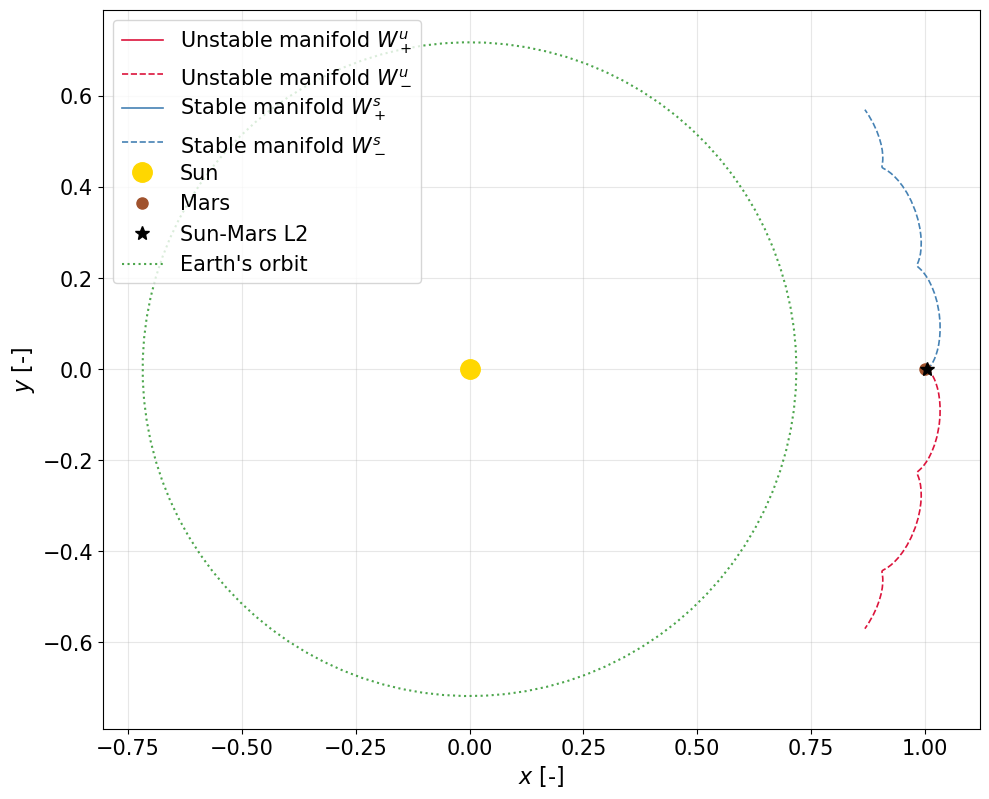

In [12]:
# ── System-wide view ──────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 10))

# Mars position in the rotating frame (at x = 1 - mu, y = 0)
x_mars = 1 - mass_ratio_sun_mars

# Manifold trajectories
ax.plot(sol_unstable_plus.y[0], sol_unstable_plus.y[1],
        color='crimson', lw=1.2, label='Unstable manifold $W^u_+$')
ax.plot(sol_unstable_minus.y[0], sol_unstable_minus.y[1],
        color='crimson', lw=1.2, ls='--', label='Unstable manifold $W^u_-$')
ax.plot(sol_stable_plus.y[0], sol_stable_plus.y[1],
        color='steelblue', lw=1.2, label='Stable manifold $W^s_+$')
ax.plot(sol_stable_minus.y[0], sol_stable_minus.y[1],
        color='steelblue', lw=1.2, ls='--', label='Stable manifold $W^s_-$')

# Sun (at x = -mu, y = 0) and Mars markers
ax.plot(-mass_ratio_sun_mars, 0, 'o', color='gold', ms=14, zorder=5, label='Sun')
ax.plot(x_mars, 0, 'o', color='sienna', ms=8, zorder=5, label='Mars')

# L2 marker
ax.plot(L2_mars, 0, '*', color='black', ms=10, zorder=5, label=f'Sun-Mars L2')

# Earth's orbit
ax.plot(earth_orbit[:, 0], earth_orbit[:, 1], color='green', lw=1.5, ls=':', alpha=0.7, label="Earth's orbit")

ax.set_xlabel(r'$x$ [-]', fontsize=FONTSIZE_XLABEL_YLABEL)
ax.set_ylabel(r'$y$ [-]', fontsize=FONTSIZE_XLABEL_YLABEL)
# ax.set_title('System-wide view — Sun-Mars invariant manifolds', fontsize=FONTSIZE_SMALL)
ax.set_aspect('equal')
ax.tick_params(labelsize=FONTSIZE_TICKS)
ax.legend(fontsize=FONTSIZE_LEGEND, loc='upper left')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('figures/wp4_manifolds_system_wide.pdf', dpi=150, bbox_inches='tight')
plt.show()

Close-up view of the projections of the manifolds: 

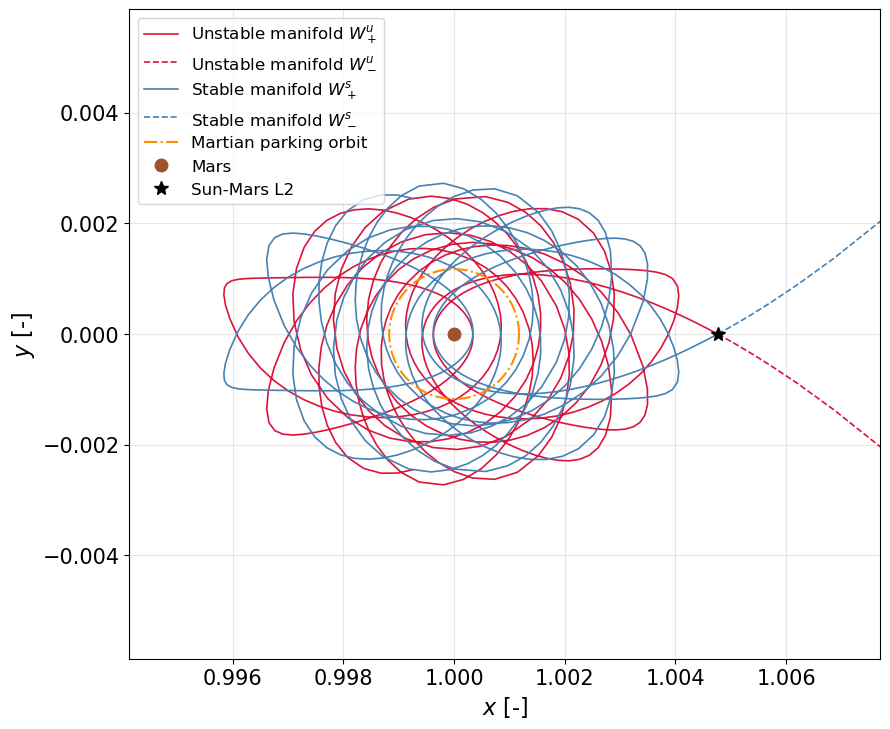

In [13]:
# ── Close-up view near Mars ───────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 9))

x_mars = 1 - mass_ratio_sun_mars

# Manifold trajectories
ax.plot(sol_unstable_plus.y[0], sol_unstable_plus.y[1],
        color='crimson', lw=1.2, label='Unstable manifold $W^u_+$')
ax.plot(sol_unstable_minus.y[0], sol_unstable_minus.y[1],
        color='crimson', lw=1.2, ls='--', label='Unstable manifold $W^u_-$')
ax.plot(sol_stable_plus.y[0], sol_stable_plus.y[1],
        color='steelblue', lw=1.2, label='Stable manifold $W^s_+$')
ax.plot(sol_stable_minus.y[0], sol_stable_minus.y[1],
        color='steelblue', lw=1.2, ls='--', label='Stable manifold $W^s_-$')
        
# Martian parking orbit (circle of radius radius_parking centred on Mars)
theta = np.linspace(0, 2 * np.pi, 1000)
ax.plot(x_mars + radius_parking * np.cos(theta),
        radius_parking * np.sin(theta),
        color='darkorange', lw=1.5, ls='-.', label='Martian parking orbit')

# Mars and L2 markers
ax.plot(x_mars, 0, 'o', color='sienna', ms=9, zorder=5, label='Mars')
ax.plot(L2_mars, 0, '*', color='black', ms=10, zorder=5, label='Sun-Mars L2')

# Set axis limits centred on Mars with some margin
margin = 5 * radius_parking
ax.set_xlim(x_mars - margin, L2_mars + margin * 0.5)
ax.set_ylim(-margin, margin)

ax.set_xlabel(r'$x$ [-]', fontsize=FONTSIZE_XLABEL_YLABEL)
ax.set_ylabel(r'$y$ [-]', fontsize=FONTSIZE_XLABEL_YLABEL)
# ax.set_title('Close-up view — manifold structure near Mars', fontsize=FONTSIZE_SMALL)
ax.set_aspect('equal')
ax.tick_params(labelsize=FONTSIZE_TICKS)
ax.legend(fontsize=FONTSIZE_LEGEND-3, loc='upper left')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('figures/wp4_manifolds_closeup.pdf', dpi=150, bbox_inches='tight')
plt.show()

## Task 4.2b 

To compute the $\Delta V$ for the required transfer, it will be assessed among all the intersection points. Notably, because the transfer happens from the manifold to the orbit, only the unstable manifold needs to be evaluated. Because the output of the integrator is a dense one, the solution can be iterated to find the exact crossing times.

Careful when considering the transformations from inertial velocities and positions into rotating frame ones.

In [14]:
def find_orbit_crossings(sol, center_x=1-mass_ratio_sun_mars, center_y=0, radius=radius_parking):
    """Find times and states when trajectory crosses a circular orbit."""
    t_eval = np.linspace(sol.t[0], sol.t[-1], len(sol.t))
    pos = sol.sol(t_eval)[:2]
    
    dist_error = np.sqrt((pos[0] - center_x)**2 + (pos[1] - center_y)**2) - radius
    crossing_idx = np.where(np.diff(np.sign(dist_error)))[0]
    
    crossing_times, crossing_states = [], []
    
    for idx in crossing_idx:
        def dist_func(t):
            s = sol.sol(t)
            return np.sqrt((s[0] - center_x)**2 + (s[1] - center_y)**2) - radius
        
        t_cross = newton(dist_func, (t_eval[idx] + t_eval[idx + 1]) / 2)
        crossing_times.append(t_cross)
        crossing_states.append(sol.sol(t_cross))
    
    return np.array(crossing_times), np.array(crossing_states)

Find crossings for unstable manifold:

In [15]:
t_cross_unstable_plus, states_cross_unstable_plus = find_orbit_crossings(sol_unstable_plus)
t_cross_unstable_minus, states_cross_unstable_minus = find_orbit_crossings(sol_unstable_minus)

print(f"Unstable+ crossings: {len(t_cross_unstable_plus)} at times {t_cross_unstable_plus}.")
print(f"Unstable- crossings: {len(t_cross_unstable_minus)} at times {t_cross_unstable_minus}.")

Unstable+ crossings: 10 at times [ 2.68699762  2.80475355  6.39101456  6.49651966  8.50697533  8.62366617
 13.57353563 13.68868573 15.58598586 15.69401422].
Unstable- crossings: 0 at times [].


We only need to consider the positive branch. Computing the required velocity vector at each point. 
$$v_{circ} = \sqrt{\frac{\mu_{\text{Mars}}}{R_{\text{parking}}}}$$
From now onwards (in this task) the magnides are dimensional. 

In [16]:
velocity_parking = np.sqrt(mu_mars / radius_mars_parking_orbit) * 1e3

Conversion of the crossing states to dimensional units and to the rotating frame:

In [17]:
states_cross_unstable_plus[:, 0:2] -= np.array([1 - mass_ratio_sun_mars, 0.0]) # to shift th ecenter
position_cross = states_cross_unstable_plus[:, 0:2]*length_unit_sun_mars # km
velocity_cross_rot = states_cross_unstable_plus[:, 2:4]*length_unit_sun_mars / time_unit_sun_mars * 1e3 # m/s
omega_physical = 1.0 / time_unit_sun_mars
x_mars_km = (1 - mass_ratio_sun_earth) * length_unit_sun_mars
pos_cross_suncentered = position_cross + np.array([x_mars_km, 0.0])  # km
omega_cross_r = omega_physical * np.column_stack([-pos_cross_suncentered[:, 1], pos_cross_suncentered[:, 0]]) * 1e3  # m/s

Now, we calculate the direction that the velocity vector needs to have in each of the crossing points (tangential to the orbit). After that, the vector is scaled to have the magnitude of the proper velocity vector. 

In [18]:
vel_cross_inertial = velocity_cross_rot + omega_cross_r  # m/s
v_mars = omega_physical * x_mars_km * 1e3  # m/s 
vel_cross_mars = vel_cross_inertial - np.array([0.0, v_mars])  
velocity_orientation_orbit = np.arctan2(position_cross[:, 1], position_cross[:, 0])
v_orbit_unit = np.column_stack([-np.sin(velocity_orientation_orbit), np.cos(velocity_orientation_orbit)])
v_orbit = velocity_parking * v_orbit_unit  # m/s

And, finally, the required $\Delta V$ is computed. The value taken is the minimum of the possible during the integration window. Since the assignment does not specify if the orbit needs to be prograde or retrograde, the minimum of them is considered. 

In [19]:
deltaV_prograde = np.linalg.norm(v_orbit - vel_cross_mars, axis=1)
deltaV_retrograde = np.linalg.norm(-v_orbit - vel_cross_mars, axis=1)
deltaV_m = np.minimum(deltaV_prograde, deltaV_retrograde)

print(f"DeltaV for Mars insertion (m/s): {deltaV_m}")
idx_min = np.argmin(deltaV_m)
# idx_min = 1 # if we want to force the first crossing
minimum_deltaV = deltaV_m[idx_min]
print(f"Minimum DeltaV for Mars insertion (m/s): {minimum_deltaV:.3f}")
t_insertion = t_cross_unstable_plus[idx_min] * time_unit_sun_mars / year_in_seconds
print(f"Time of minimum DeltaV insertion: {t_insertion:.5f} Earth years.")

DeltaV for Mars insertion (m/s): [319.05578445 319.38176403 399.59659349 400.08913905 224.08652683
 225.70760156 217.41990685 215.72167318 385.88174427 385.59166141]
Minimum DeltaV for Mars insertion (m/s): 215.722
Time of minimum DeltaV insertion: 3.58010 Earth years.


### Plot of the maneuver up to the transfer 

Similar close-up view as before. 

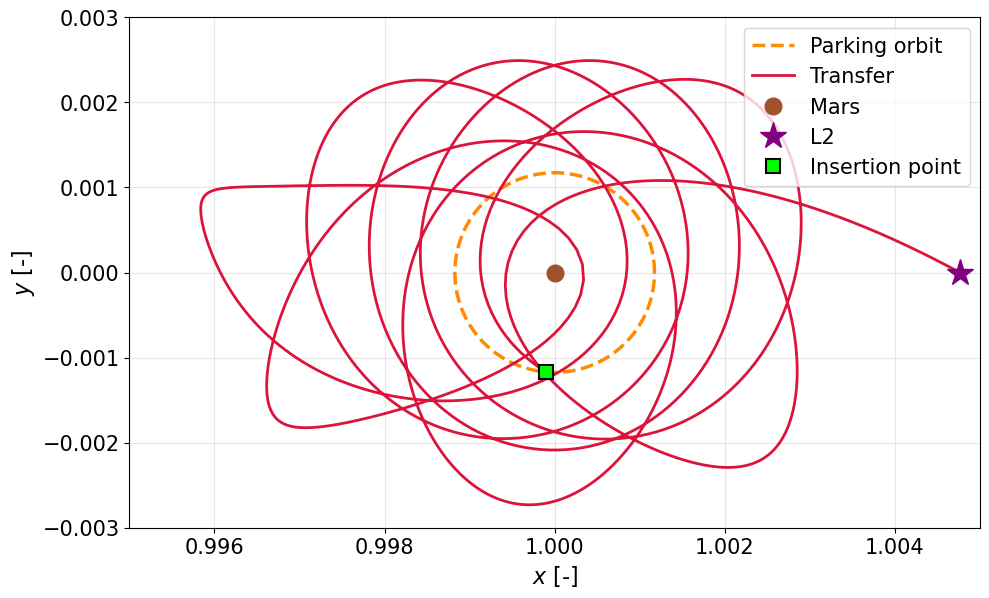

In [20]:
fig, ax = plt.subplots(figsize=(10, 10))

t_intersection = t_cross_unstable_plus[idx_min]

t_transfer = np.linspace(0, t_intersection, 3000)
traj_transfer = sol_unstable_plus.sol(t_transfer)

theta = np.linspace(0, 2*np.pi, 300)
parking_orbit_x = x_mars + radius_parking * np.cos(theta)
parking_orbit_y = radius_parking * np.sin(theta)

intersection_x = states_cross_unstable_plus[idx_min, 0] + x_mars
intersection_y = states_cross_unstable_plus[idx_min, 1]

ax.plot(parking_orbit_x, parking_orbit_y, color='darkorange', lw=2.5, 
        ls='--', label='Parking orbit', zorder=2)
ax.plot(traj_transfer[0], traj_transfer[1], color='crimson', lw=2.0, 
        label='Transfer', zorder=3)
ax.plot(x_mars, 0, 'o', color='sienna', ms=12, label='Mars', zorder=4)
ax.plot(L2_mars, 0.0, '*', color='purple', ms=20, 
        label='L2', zorder=5)
ax.plot(intersection_x, intersection_y, 's', color='lime', ms=10, 
        label='Insertion point', zorder=6, markeredgecolor='black', markeredgewidth=1.5)

ax.set_xlim(0.995, 1.005)
ax.set_ylim(-0.003, 0.003)
ax.set_xlabel(r'$x$ [-]', fontsize=FONTSIZE_XLABEL_YLABEL)
ax.set_ylabel(r'$y$ [-]', fontsize=FONTSIZE_XLABEL_YLABEL)
# ax.set_title('Transfer from L2 to Mars Parking Orbit', fontsize=FONTSIZE_TITLE)
ax.set_aspect('equal')
ax.tick_params(labelsize=FONTSIZE_TICKS)
ax.legend(fontsize=FONTSIZE_LEGEND, loc='best')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('figures/wp4_transfer_closeup.pdf', dpi=150, bbox_inches='tight')
plt.show()

## Task 4.3

Now, we need to use the ideal solar-sail acceleration model for propagating the EOM. For the personal problem specification (L2), the following legs need to be computed:

1. **Earth -> L2**: Stable right (adding a positive perturbation along the eigenvector: stable plus)
2. **L2 -> Mars parking orbit**: Unstable left (adding a negative perturbation along the eigenvector: unstable minus)

In [21]:
cone_angles = np.linspace(-90, 90, 73) # hardcoding the 2.5 diff
cone_angles_rad = np.radians(cone_angles)

beta_problem = lightness_number

### Earth to L2 transfer

In [22]:
alpha_values_earth_l2 = []
crossings_earth_l2 = []
deltaV_min_earth_l2 = []
time_min_earth_l2 = []

for alpha in cone_angles_rad:
    sol_solar_sail = solve_ivp(eom, [0, -time_span], state0_unstable_plus, args=(mass_ratio_sun_mars, beta_problem, alpha), method='DOP853', rtol=tolerance, atol=tolerance, dense_output=True)
    t_cross_solar_sail_earth_l2, states_cross_solar_sail_earth_l2 = find_orbit_crossings(sol_solar_sail, center_x=-mass_ratio_sun_mars, center_y=0, radius=distance_earth)
    if len(t_cross_solar_sail_earth_l2) > 0:
        pos_cross = states_cross_solar_sail_earth_l2[:, 0:2] * length_unit_sun_mars # km
        pos_cross_sun = pos_cross - np.array([-mass_ratio_sun_mars, 0]) * length_unit_sun_mars
        vel_cross = states_cross_solar_sail_earth_l2[:, 2:4] * length_unit_sun_mars / time_unit_sun_mars * 1e3 # m/s
        # print(vel_cross)

        velocity_earth_inertial = np.sqrt(mu_sun / AU) * 1e3  # m/s

        angle_cross = np.arctan2(pos_cross_sun[:, 1], pos_cross_sun[:, 0])
        v_earth_inertial = velocity_earth_inertial * np.column_stack([-np.sin(angle_cross), np.cos(angle_cross)])  # m/s
        omega_physical = 1.0 / time_unit_sun_mars  # rad/s
        omega_cross_r = omega_physical * np.column_stack([-pos_cross[:, 1], pos_cross[:, 0]]) * 1e3 # m/s

        v_earth_rot = v_earth_inertial - omega_cross_r  # m/s

        deltaV_prograde = np.linalg.norm(v_earth_rot - vel_cross, axis=1)
        deltaV_retrograde = np.linalg.norm(-v_earth_rot - vel_cross, axis=1)
        # print("DeltaV prograde:", deltaV_prograde) # debugging
        # print("DeltaV retrograde:", deltaV_retrograde) # debugging
        deltaV_m = np.minimum(deltaV_prograde, deltaV_retrograde)
        is_prograde = deltaV_prograde < deltaV_retrograde

        idx_min = np.argmin(deltaV_m)
        minimum_deltaV = deltaV_m[idx_min]
        t_min = t_cross_solar_sail_earth_l2[idx_min] * time_unit_sun_mars / year_in_seconds # years

        alpha_values_earth_l2.append(np.degrees(alpha))
        crossings_earth_l2.append(len(t_cross_solar_sail_earth_l2))
        deltaV_min_earth_l2.append(minimum_deltaV)
        time_min_earth_l2.append(t_min)

        print(f"Alpha: {np.degrees(alpha):6.1f} deg; crossings: {len(t_cross_solar_sail_earth_l2)}; min deltaV: {minimum_deltaV:.3f} m/s; t: {abs(t_min):.5f} yr")

# Convert to numpy arrays for easier manipulation
alpha_values_earth_l2 = np.array(alpha_values_earth_l2)
crossings_earth_l2 = np.array(crossings_earth_l2)
deltaV_min_earth_l2 = np.array(deltaV_min_earth_l2)
time_min_earth_l2 = np.array(time_min_earth_l2)


Alpha:  -55.0 deg; crossings: 1; min deltaV: 896.850 m/s; t: 4.85767 yr
Alpha:  -52.5 deg; crossings: 1; min deltaV: 488.424 m/s; t: 4.51527 yr
Alpha:  -50.0 deg; crossings: 1; min deltaV: 834.589 m/s; t: 3.91349 yr
Alpha:  -47.5 deg; crossings: 1; min deltaV: 1178.752 m/s; t: 3.75031 yr
Alpha:  -45.0 deg; crossings: 1; min deltaV: 1351.485 m/s; t: 3.64064 yr
Alpha:  -42.5 deg; crossings: 1; min deltaV: 1441.459 m/s; t: 3.56497 yr
Alpha:  -40.0 deg; crossings: 1; min deltaV: 1493.578 m/s; t: 3.51731 yr
Alpha:  -37.5 deg; crossings: 1; min deltaV: 1536.663 m/s; t: 3.49554 yr
Alpha:  -35.0 deg; crossings: 1; min deltaV: 1586.876 m/s; t: 3.49891 yr
Alpha:  -32.5 deg; crossings: 1; min deltaV: 1646.373 m/s; t: 3.52697 yr
Alpha:  -30.0 deg; crossings: 1; min deltaV: 1702.150 m/s; t: 3.57931 yr
Alpha:  -27.5 deg; crossings: 1; min deltaV: 1725.720 m/s; t: 3.65612 yr
Alpha:  -25.0 deg; crossings: 1; min deltaV: 1669.944 m/s; t: 3.75928 yr
Alpha:  -22.5 deg; crossings: 1; min deltaV: 1450.881 

### L2 to Mars parking orbit transfer

In [23]:
alpha_values_l2_parking = []
crossings_l2_parking = []
deltaV_min_l2_parking = []
time_min_l2_parking = []

x_mars_dim = (1 - mass_ratio_sun_mars) * length_unit_sun_mars  # km

for alpha in cone_angles_rad:
    sol_solar_sail = solve_ivp(eom, [0, time_span], state0_stable_minus, args=(mass_ratio_sun_mars, beta_problem, alpha), method='DOP853', rtol=tolerance, atol=tolerance, dense_output=True)
    t_cross_solar_sail_l2_parking, states_cross_solar_sail_l2_parking = find_orbit_crossings(sol_solar_sail)
    if len(t_cross_solar_sail_l2_parking) > 0:
        # Shift to Mars-centered frame (consistent with Task 4.2b)
        pos_cross_mars = (states_cross_solar_sail_l2_parking[:, 0:2] - np.array([1 - mass_ratio_sun_mars, 0.0])) * length_unit_sun_mars  # km
        vel_cross = states_cross_solar_sail_l2_parking[:, 2:4] * length_unit_sun_mars / time_unit_sun_mars * 1e3  # m/s

        velocity_parking = np.sqrt(mu_mars / radius_mars_parking_orbit) * 1e3  # m/s

        # Angle from Mars center, tangential direction
        angle_cross = np.arctan2(pos_cross_mars[:, 1], pos_cross_mars[:, 0])
        v_parking_unit = np.column_stack([-np.sin(angle_cross), np.cos(angle_cross)])  # tangential, not radial
        v_parking = velocity_parking * v_parking_unit  # m/s

        deltaV_prograde = np.linalg.norm(v_parking - vel_cross, axis=1)
        deltaV_retrograde = np.linalg.norm(-v_parking - vel_cross, axis=1)
        deltaV_m = np.minimum(deltaV_prograde, deltaV_retrograde)

        idx_min = np.argmin(deltaV_m)
        minimum_deltaV = deltaV_m[idx_min]
        t_min = t_cross_solar_sail_l2_parking[idx_min] * time_unit_sun_mars / year_in_seconds  # years

        alpha_values_l2_parking.append(np.degrees(alpha))
        crossings_l2_parking.append(len(t_cross_solar_sail_l2_parking))
        deltaV_min_l2_parking.append(minimum_deltaV)
        time_min_l2_parking.append(t_min)

        print(f"Alpha: {np.degrees(alpha):6.1f} deg; crossings: {len(t_cross_solar_sail_l2_parking)}; min deltaV: {minimum_deltaV:.3f} m/s; t: {t_min:.5f} yr")

alpha_values_l2_parking = np.array(alpha_values_l2_parking)
crossings_l2_parking = np.array(crossings_l2_parking)
deltaV_min_l2_parking = np.array(deltaV_min_l2_parking)
time_min_l2_parking = np.array(time_min_l2_parking)

Alpha:  -90.0 deg; crossings: 10; min deltaV: 214.915 m/s; t: 4.02308 yr
Alpha:   67.5 deg; crossings: 4; min deltaV: 238.679 m/s; t: 0.67318 yr
Alpha:   70.0 deg; crossings: 6; min deltaV: 102.858 m/s; t: 0.81941 yr
Alpha:   72.5 deg; crossings: 10; min deltaV: 114.825 m/s; t: 0.78535 yr
Alpha:   75.0 deg; crossings: 10; min deltaV: 100.709 m/s; t: 1.75713 yr
Alpha:   77.5 deg; crossings: 20; min deltaV: 145.814 m/s; t: 3.20235 yr
Alpha:   80.0 deg; crossings: 20; min deltaV: 119.932 m/s; t: 1.10156 yr
Alpha:   82.5 deg; crossings: 14; min deltaV: 146.651 m/s; t: 4.45055 yr
Alpha:   85.0 deg; crossings: 10; min deltaV: 240.669 m/s; t: 2.14713 yr
Alpha:   87.5 deg; crossings: 10; min deltaV: 250.844 m/s; t: 2.30210 yr
Alpha:   90.0 deg; crossings: 10; min deltaV: 214.915 m/s; t: 4.02308 yr


### Plotting of the results

#### $\Delta V$ plots

Earth -> L2 transfer

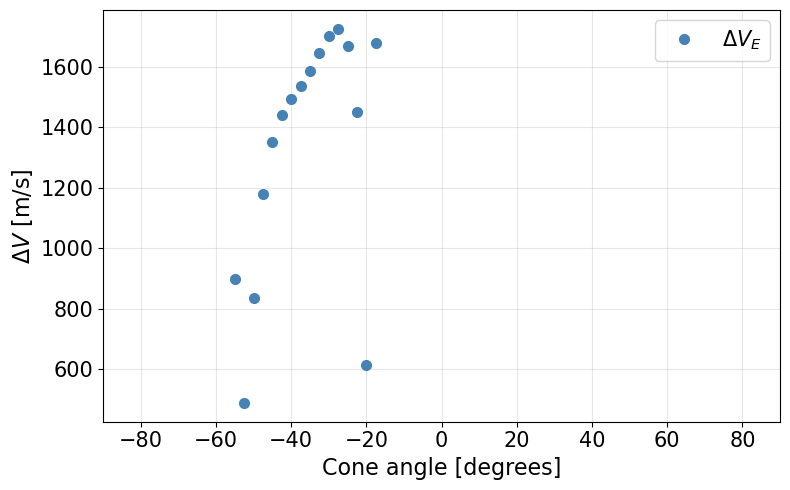

In [24]:
fig, ax1 = plt.subplots(figsize=(8, 5))

ax1.plot(alpha_values_earth_l2, deltaV_min_earth_l2, 'o', linewidth=2.5, markersize=7, 
         color='steelblue', label=r'$\Delta V_E$')
ax1.set_xlabel(r'Cone angle [degrees]', fontsize=FONTSIZE_XLABEL_YLABEL)
ax1.set_ylabel(r'$\Delta V$ [m/s]', fontsize=FONTSIZE_XLABEL_YLABEL)
ax1.set_xlim(-90, 90)
# ax1.set_title(r'Earth $\rightarrow$ L2: $\Delta V_E$ vs cone angle', fontsize=FONTSIZE_TITLE-5, pad=20)
ax1.legend(fontsize=FONTSIZE_LEGEND, loc='best')
ax1.grid(True, alpha=0.3)
ax1.tick_params(labelsize=FONTSIZE_TICKS)

plt.tight_layout()
plt.savefig('figures/wp4_deltaV_earth_l2.pdf', dpi=150, bbox_inches='tight')
plt.show()

L2 -> Mars parking orbit transfer

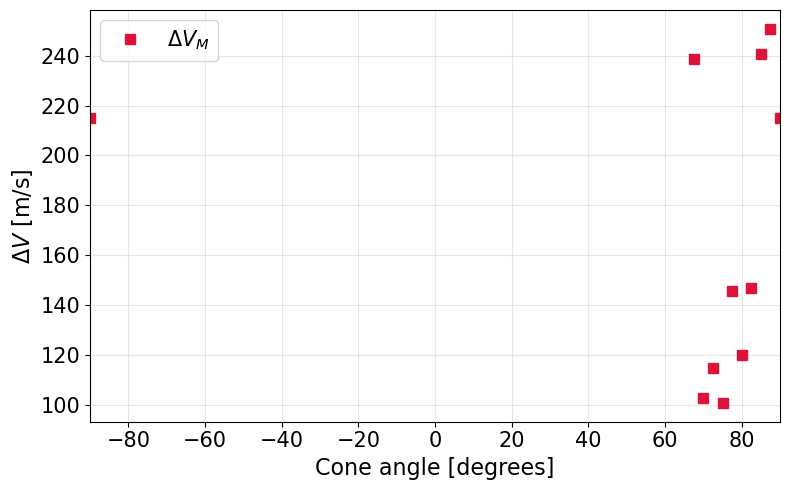

In [25]:
fig, ax2 = plt.subplots(figsize=(8, 5))

ax2.plot(alpha_values_l2_parking, deltaV_min_l2_parking, 's', linewidth=2.5, markersize=7, 
         color='crimson', label=r'$\Delta V_M$')
ax2.set_xlabel(r'Cone angle [degrees]', fontsize=FONTSIZE_XLABEL_YLABEL)
ax2.set_ylabel(r'$\Delta V$ [m/s]', fontsize=FONTSIZE_XLABEL_YLABEL)
ax2.set_xlim(-90, 90)
# ax2.set_title(r'L2 $\rightarrow$ Mars: $\Delta V_M$ vs cone angle', fontsize=FONTSIZE_TITLE-5, pad=20)
ax2.legend(fontsize=FONTSIZE_LEGEND, loc='best')
ax2.grid(True, alpha=0.3)
ax2.tick_params(labelsize=FONTSIZE_TICKS)

plt.tight_layout()
plt.savefig('figures/wp4_deltaV_l2_mars.pdf', dpi=150, bbox_inches='tight')
plt.show()

### Results for the table

In [26]:
leg1_idx = np.argmin(deltaV_min_earth_l2) 
leg1_deltaV = deltaV_min_earth_l2[leg1_idx]
leg1_angle = alpha_values_earth_l2[leg1_idx]
leg1_time = time_min_earth_l2[leg1_idx]

leg2_idx = np.argmin(deltaV_min_l2_parking)
leg2_deltaV = deltaV_min_l2_parking[leg2_idx]
leg2_angle = alpha_values_l2_parking[leg2_idx]
leg2_time = time_min_l2_parking[leg2_idx]

tot_deltaV = leg1_deltaV + leg2_deltaV

print(f"Leg 1: Cone angle = {leg1_angle:.1f} deg, min DeltaV = {leg1_deltaV:.3f} m/s, time = {abs(leg1_time):.5f} yr")
print(f"Leg 2: Cone angle = {leg2_angle:.1f} deg, min DeltaV = {leg2_deltaV:.3f} m/s, time = {abs(leg2_time):.5f} yr")
print(f"Total DeltaV = {tot_deltaV:.3f} m/s")

Leg 1: Cone angle = -52.5 deg, min DeltaV = 488.424 m/s, time = 4.51527 yr
Leg 2: Cone angle = 75.0 deg, min DeltaV = 100.709 m/s, time = 1.75713 yr
Total DeltaV = 589.133 m/s


#### Trajectory plotting

System-wide view

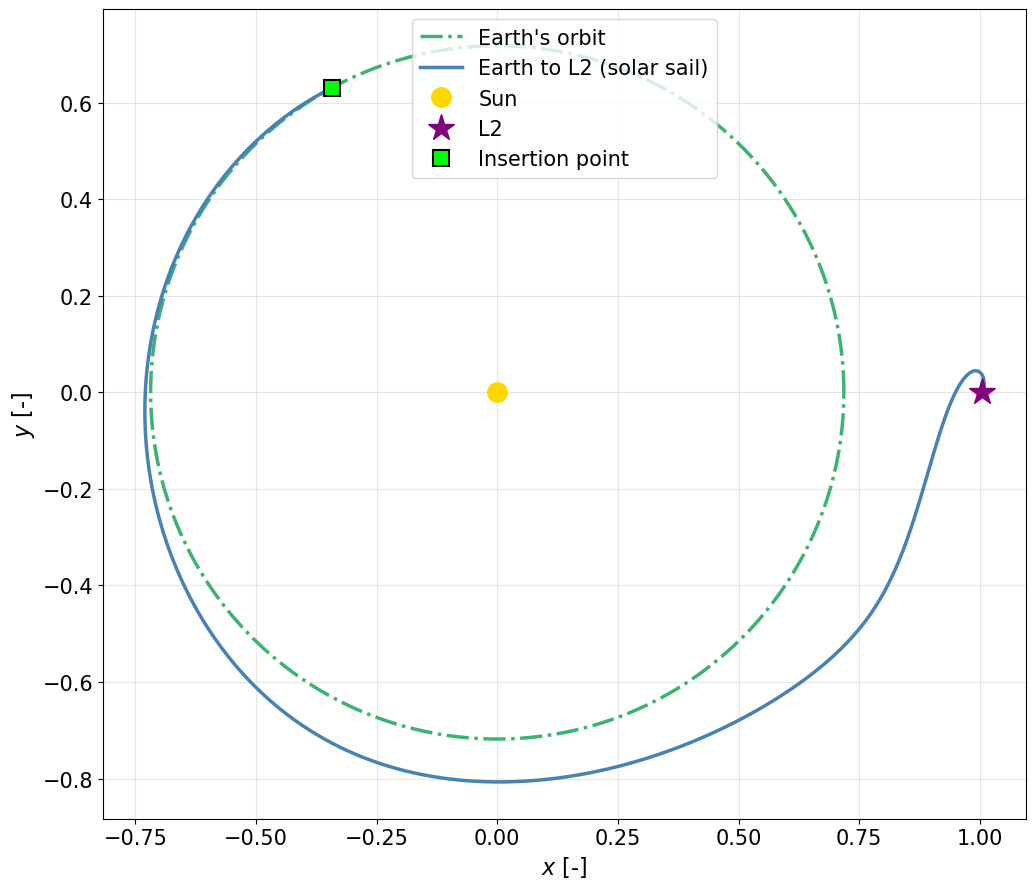

In [27]:
# Leg 1: Earth -> L2 with optimal cone angle
alpha_leg1 = np.radians(leg1_angle)
sol_leg1 = solve_ivp(eom, [0, -time_span], state0_unstable_plus, args=(mass_ratio_sun_mars, beta_problem, alpha_leg1), method='DOP853', rtol=tolerance, atol=tolerance, dense_output=True)
t_cross_leg1, states_cross_leg1 = find_orbit_crossings(sol_leg1, center_x=-mass_ratio_sun_mars, center_y=0, radius=distance_earth)

if len(t_cross_leg1) > 0:
    pos_cross = states_cross_leg1[:, 0:2] * length_unit_sun_mars # km
    pos_cross_sun = pos_cross - np.array([-mass_ratio_sun_mars, 0]) * length_unit_sun_mars
    vel_cross = states_cross_leg1[:, 2:4] * length_unit_sun_mars / time_unit_sun_mars * 1e3 # m/s

    velocity_earth_inertial = np.sqrt(mu_sun / AU) * 1e3  # m/s

    angle_cross = np.arctan2(pos_cross_sun[:, 1], pos_cross_sun[:, 0])
    v_earth_inertial = velocity_earth_inertial * np.column_stack([-np.sin(angle_cross), np.cos(angle_cross)])  # m/s
    omega_physical = 1.0 / time_unit_sun_mars  # rad/s
    omega_cross_r = omega_physical * np.column_stack([-pos_cross[:, 1], pos_cross[:, 0]]) * 1e3 # m/s

    v_earth_rot = v_earth_inertial - omega_cross_r  # m/s

    deltaV_prograde = np.linalg.norm(v_earth_rot - vel_cross, axis=1)
    deltaV_retrograde = np.linalg.norm(-v_earth_rot - vel_cross, axis=1)
    deltaV_m = np.minimum(deltaV_prograde, deltaV_retrograde)

    idx_min_leg1 = np.argmin(deltaV_m)
    t_insertion_leg1 = t_cross_leg1[idx_min_leg1]

# Leg 2: L2 -> Mars with optimal cone angle
alpha_leg2 = np.radians(leg2_angle)
sol_leg2 = solve_ivp(eom, [0, time_span], state0_stable_minus, args=(mass_ratio_sun_mars, beta_problem, alpha_leg2), method='DOP853', rtol=tolerance, atol=tolerance, dense_output=True)
t_cross_leg2, states_cross_leg2 = find_orbit_crossings(sol_leg2)

if len(t_cross_leg2) > 0:
    pos_cross_mars = (states_cross_leg2[:, 0:2] - np.array([1 - mass_ratio_sun_mars, 0.0])) * length_unit_sun_mars  # km
    vel_cross = states_cross_leg2[:, 2:4] * length_unit_sun_mars / time_unit_sun_mars * 1e3  # m/s

    velocity_parking = np.sqrt(mu_mars / radius_mars_parking_orbit) * 1e3  # m/s

    angle_cross = np.arctan2(pos_cross_mars[:, 1], pos_cross_mars[:, 0])
    v_parking_unit = np.column_stack([-np.sin(angle_cross), np.cos(angle_cross)])  
    v_parking = velocity_parking * v_parking_unit  # m/s

    deltaV_prograde = np.linalg.norm(v_parking - vel_cross, axis=1)
    deltaV_retrograde = np.linalg.norm(-v_parking - vel_cross, axis=1)
    deltaV_m = np.minimum(deltaV_prograde, deltaV_retrograde)

    idx_min_leg2 = np.argmin(deltaV_m)
    t_insertion_leg2 = t_cross_leg2[idx_min_leg2]

# Plot: Leg 1 - Earth to L2 transfer
fig, ax = plt.subplots(figsize=(11, 9))

t_leg1 = np.linspace(0, t_insertion_leg1, 2000)
traj_leg1 = sol_leg1.sol(t_leg1)

theta_earth = np.linspace(0, 2*np.pi, 300)
earth_orbit_plot = distance_earth * np.array([[np.cos(t) - mass_ratio_sun_earth, np.sin(t)] for t in theta_earth])

ax.plot(earth_orbit_plot[:, 0], earth_orbit_plot[:, 1], color='mediumseagreen', lw=2.5, ls='-.', label="Earth's orbit", zorder=2)
ax.plot(traj_leg1[0], traj_leg1[1], color='steelblue', lw=2.5, label='Earth to L2 (solar sail)', zorder=3)
# ax.plot(-mass_ratio_sun_earth, 0, 'o', color='cyan', ms=10, label='Earth', zorder=5)
ax.plot(-mass_ratio_sun_mars, 0, 'o', color='gold', ms=14, label='Sun', zorder=5)
ax.plot(L2_mars, 0, '*', color='purple', ms=20, label='L2', zorder=5)
ax.plot(traj_leg1[0, -1], traj_leg1[1, -1], 's', color='lime', ms=11, label='Insertion point', zorder=6, markeredgecolor='black', markeredgewidth=1.5)


ax.set_xlabel(r'$x$ [-]', fontsize=FONTSIZE_XLABEL_YLABEL)
ax.set_ylabel(r'$y$ [-]', fontsize=FONTSIZE_XLABEL_YLABEL)
ax.set_aspect('equal')
ax.tick_params(labelsize=FONTSIZE_TICKS)
ax.legend(fontsize=FONTSIZE_LEGEND, loc='upper center')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('figures/wp4_trajectory_earth_l2.pdf', dpi=150, bbox_inches='tight')
plt.show()

Close-up view:

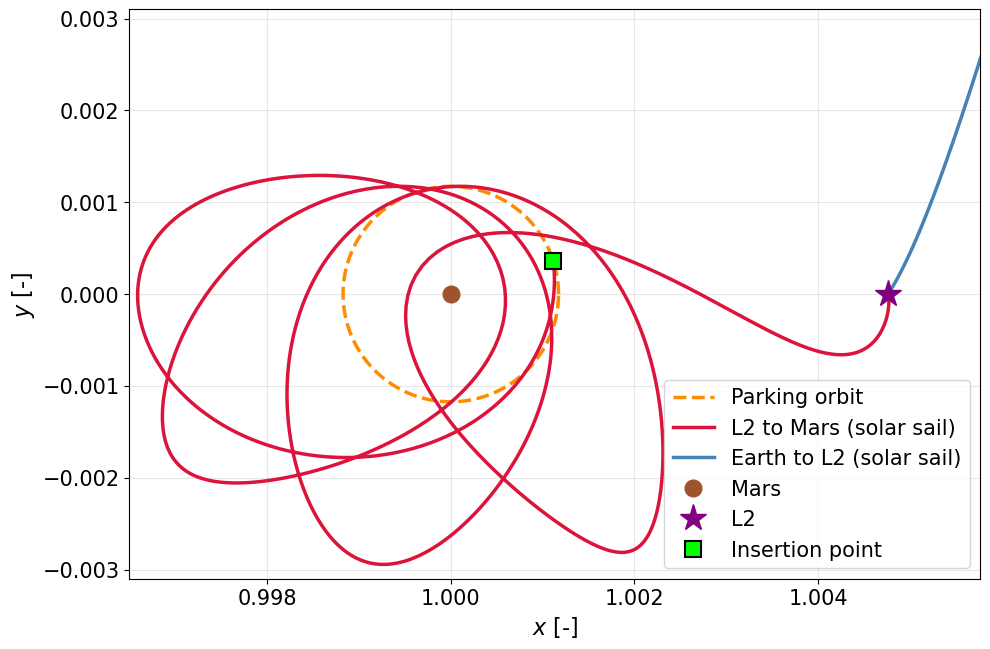

In [28]:
fig, ax = plt.subplots(figsize=(10, 10))

t_leg2 = np.linspace(0, t_insertion_leg2, 2000)
traj_leg2 = sol_leg2.sol(t_leg2)

x_mars = 1 - mass_ratio_sun_mars
theta = np.linspace(0, 2*np.pi, 300)
parking_orbit_x = x_mars + radius_parking * np.cos(theta)
parking_orbit_y = radius_parking * np.sin(theta)

ax.plot(parking_orbit_x, parking_orbit_y, color='darkorange', lw=2.5, ls='--', label='Parking orbit', zorder=2)
ax.plot(traj_leg2[0], traj_leg2[1], color='crimson', lw=2.5, label='L2 to Mars (solar sail)', zorder=3)
ax.plot(traj_leg1[0], traj_leg1[1], color='steelblue', lw=2.5, label='Earth to L2 (solar sail)', zorder=3)
ax.plot(x_mars, 0, 'o', color='sienna', ms=12, label='Mars', zorder=4)
ax.plot(L2_mars, 0, '*', color='purple', ms=20, label='L2', zorder=5)
ax.plot(traj_leg2[0, -1], traj_leg2[1, -1], 's', color='lime', ms=11, label='Insertion point', zorder=6, markeredgecolor='black', markeredgewidth=1.5)

ax.set_xlabel(r'$x$ [-]', fontsize=FONTSIZE_XLABEL_YLABEL)
ax.set_ylabel(r'$y$ [-]', fontsize=FONTSIZE_XLABEL_YLABEL)
ax.set_aspect('equal')
ax.set_xlim(x_mars - 0.0035, L2_mars + 0.001)
ax.set_ylim(-0.0031, 0.0031)
ax.tick_params(labelsize=FONTSIZE_TICKS)
ax.legend(fontsize=FONTSIZE_LEGEND, loc='best')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('figures/wp4_trajectory_l2_mars.pdf', dpi=150, bbox_inches='tight')
plt.show()

## Task 4.5

In [29]:
angle_at_epoch_deg = 122.35 # deg
angle_at_epoch = np.radians(angle_at_epoch_deg)
initial_epoch = datetime.strptime("2030-01-01", "%Y-%m-%d")  

To compute the feasibility, first we compute the angle travelled since departure. 

In [30]:
departure_point = np.array([traj_leg1[0, -1]+mass_ratio_sun_mars, traj_leg1[1, -1]])
angle_departure = np.arctan2(departure_point[1], departure_point[0])
angle_arrival = np.arctan2(0, x_mars)
angle_traveled = angle_arrival - angle_departure
angle_traveled_deg = np.degrees(angle_traveled) % 360 # to fit in [0, 360]
print(f"Angle traveled around the Sun from Earth to Mars: {angle_traveled_deg:.1f} degrees")

Angle traveled around the Sun from Earth to Mars: 241.5 degrees


And now take into account Mars' motion during flight. 

In [31]:
t_flight = abs(t_insertion_leg1 * time_unit_sun_mars) # s
angle_mars_flight = omega_physical * t_flight
angle_mars_flight_deg = np.degrees(angle_mars_flight) % 360
print(f"Angle Mars travels during flight time: {angle_mars_flight_deg:.1f} degrees")

Angle Mars travels during flight time: 269.2 degrees


So the difference that needs to occur at launch is:

In [32]:
angle_at_launch = angle_mars_flight - angle_traveled
angle_at_launch_deg = np.degrees(angle_at_launch) % 360
print(f"Optimal launch angle (relative to Mars position at launch): {angle_at_launch_deg:.1f} degrees")

Optimal launch angle (relative to Mars position at launch): 27.7 degrees


Accounting for Earth's and Mars mean motions, we compute the time that happens since the reference epoch and position until the planets are at the required relative position.

In [33]:
omega_earth = 2 * np.pi / year_in_seconds  # rad/s
omega_relative = omega_physical - omega_earth
time_alignment = (angle_at_launch - angle_at_epoch) % (2 * np.pi) / abs(omega_relative)
time_alignment

np.float64(59419815.05115257)

So the arrival epoch is:

In [34]:
arrival_date = initial_epoch + timedelta(seconds=t_flight) + timedelta(seconds=time_alignment)

print(f"Initial epoch date: {initial_epoch.strftime('%Y-%m-%d')}")
print(f"Optimal launch date: {(initial_epoch + timedelta(seconds=time_alignment)).strftime('%Y-%m-%d')}")
print(f"Arrival date: {arrival_date.strftime('%Y-%m-%d')}")
print(f"Flight time: {t_flight / (24 * 3600):.2f} days")
print(f"Time until optimal launch from initial epoch: {time_alignment / (24 * 3600 * 365.25):.2f} years")

Initial epoch date: 2030-01-01
Optimal launch date: 2031-11-19
Arrival date: 2036-05-25
Flight time: 1649.23 days
Time until optimal launch from initial epoch: 1.88 years
